In [63]:
using Pkg
Pkg.activate("path/to/project")
using MajoranaPropagation
using Revise
using PauliPropagation
using Plots
using LaTeXStrings
using Measures

  Activating project at `c:\Users\jugro\Desktop\8Sem_ETH\Research Project\Simulations\path\to\project`


In [64]:
N_x = 4
N_y = 4
N_spinful_sites = N_x * N_y
t = 1.
U = 2.

n_layers = 15
dt = 0.1

min_abs_coeff1 = 1.e-4
min_abs_coeff2 = 1.e-5
max_unpaired = 4
unpaired_mask = create_unpaired_mask(2 * N_spinful_sites);

topo = rectangletopology(N_x, N_y)

circ_single = []
thetas_single = []

#up hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopup, [i, j]))
    push!(thetas_single, -t * dt)
end

#down hoppings 
for (i, j) in topo
    push!(circ_single, FermionicGate(:hopdn, [i, j]))
    push!(thetas_single, -t * dt)
end

#on-site repulsion 
for i = 1:N_spinful_sites
    push!(circ_single, FermionicGate(:nupndn, i))
    push!(thetas_single, U * dt)
end

#initial state 
initial_state_label = "checkerboard"
is_spinful = true
hole_pos = 6
coeffs = [1/sqrt(2), 1/sqrt(2)]
initial_state_dnup = FockState(N_spinful_sites, [1,3,8,9,11,14,16],[2,4,5,7,10,12,13,15])#7 is down, 11 is up
initial_state_updn = FockState(N_spinful_sites, [1,3,7,8,9,14,16], [2,4,5,10,11,12,13,15]) #7 is up, 11 is down
initial_state = [initial_state_dnup, initial_state_updn]



2-element Vector{FockState{UInt64}}:
 Fock state with 15 fermions at positions
    ↑: 1, 3, 8, 9, 11, 14, 16
    ↓: 2, 4, 5, 7, 10, 12, 13, 15

 Fock state with 15 fermions at positions
    ↑: 1, 3, 7, 8, 9, 14, 16
    ↓: 2, 4, 5, 10, 11, 12, 13, 15


1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 

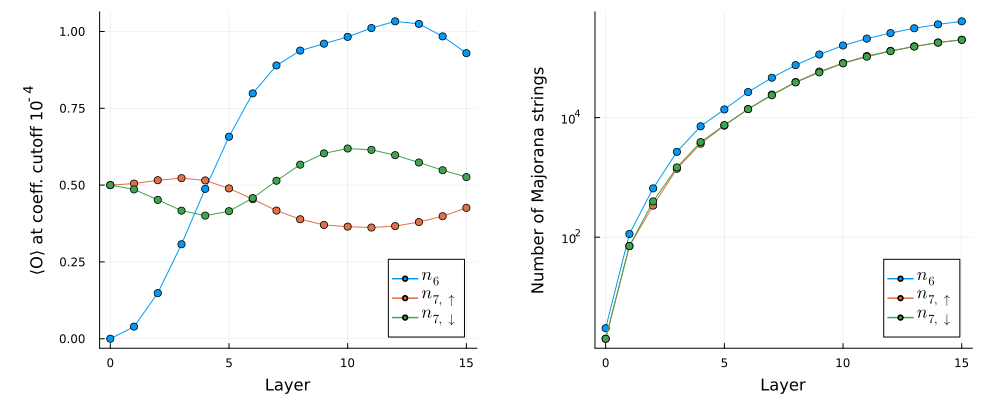

In [ ]:
obs11 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, hole_pos)) #n_6_up
obs12 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, hole_pos)) #n_6_down
obs1=obs11+obs12
obs2 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, 7)) #n_7_up
obs3 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, 7)) #n_7_down

res1 = zeros(n_layers+1)
res2 = zeros(n_layers+1)
res3 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
length2 = zeros(n_layers+1)
length3 = zeros(n_layers+1)

res1[1]=overlapwithfock(obs1, initial_state, coeffs)
length1[1] = length(obs1)
res2[1]=overlapwithfock(obs2, initial_state, coeffs)
length2[1] = length(obs2)
res3[1]=overlapwithfock(obs3, initial_state, coeffs)
length3[1] = length(obs3)
#simulation (7down, 11up) for minal coefficient 1.e-4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single, obs1, thetas_single; min_abs_coeff=min_abs_coeff1,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    propagate!(circ_single, obs2, thetas_single; min_abs_coeff=min_abs_coeff1,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    propagate!(circ_single, obs3, thetas_single; min_abs_coeff=min_abs_coeff1,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res1[j+1] = overlapwithfock(obs1, initial_state, coeffs)
    res2[j+1] = overlapwithfock(obs2, initial_state, coeffs)
    res3[j+1] = overlapwithfock(obs3, initial_state, coeffs)

    length1[j+1] = length(obs1)
    length2[j+1] = length(obs2)
    length3[j+1] = length(obs3)
end
    
ev_plot = plot(xlabel = "Layer", ylabel = ylabel = "⟨O⟩ at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 12)
plot!(ev_plot, 0:n_layers, res1, label=L"n_6", marker=:circle)
plot!(ev_plot, 0:n_layers, res2, label=L"n_{7,\uparrow}", marker=:circle)
plot!(ev_plot, 0:n_layers, res3, label=L"n_{7,\downarrow}", marker=:circle)

length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length1, label=L"n_6", marker=:circle)
plot!(length_plot, 0:n_layers, length2, label=L"n_{7,\uparrow}", marker=:circle)
plot!(length_plot, 0:n_layers, length3, label=L"n_{7,\downarrow}", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 

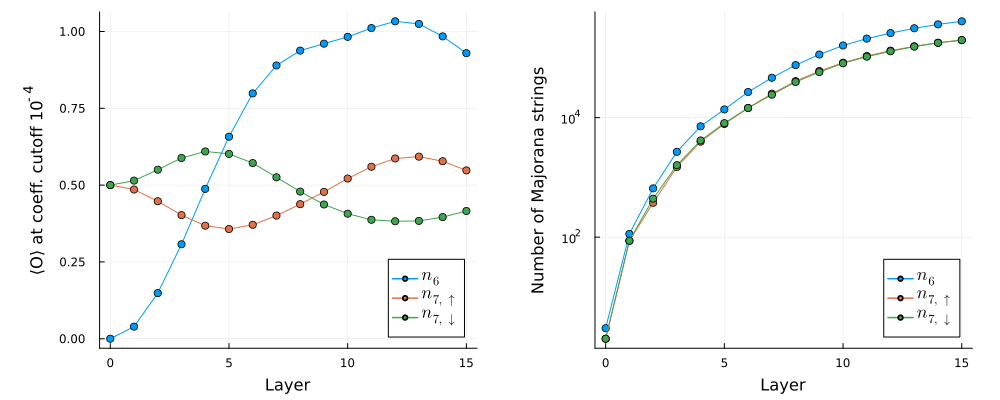

In [65]:
obs11 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, hole_pos)) #n_6_up
obs12 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, hole_pos)) #n_6_down
obs1=obs11+obs12
obs2 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, 11)) #n_11_up
obs3 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, 11)) #n_11_down

res1 = zeros(n_layers+1)
res2 = zeros(n_layers+1)
res3 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
length2 = zeros(n_layers+1)
length3 = zeros(n_layers+1)

res1[1]=overlapwithfock(obs1, initial_state, coeffs)
length1[1] = length(obs1)
res2[1]=overlapwithfock(obs2, initial_state, coeffs)
length2[1] = length(obs2)
res3[1]=overlapwithfock(obs3, initial_state, coeffs)
length3[1] = length(obs3)
#simulation (7down, 11up) for minal coefficient 1.e-4
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single, obs1, thetas_single; min_abs_coeff=min_abs_coeff1,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    propagate!(circ_single, obs2, thetas_single; min_abs_coeff=min_abs_coeff1,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    propagate!(circ_single, obs3, thetas_single; min_abs_coeff=min_abs_coeff1,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res1[j+1] = overlapwithfock(obs1, initial_state, coeffs)
    res2[j+1] = overlapwithfock(obs2, initial_state, coeffs)
    res3[j+1] = overlapwithfock(obs3, initial_state, coeffs)

    length1[j+1] = length(obs1)
    length2[j+1] = length(obs2)
    length3[j+1] = length(obs3)
end
    
ev_plot = plot(xlabel = "Layer", ylabel = ylabel = "⟨O⟩ at coeff. cutoff " *"10^{-4}", legend = :bottomright, legend_font_pointsize = 12)
plot!(ev_plot, 0:n_layers, res1, label=L"n_6", marker=:circle)
plot!(ev_plot, 0:n_layers, res2, label=L"n_{7,\uparrow}", marker=:circle)
plot!(ev_plot, 0:n_layers, res3, label=L"n_{7,\downarrow}", marker=:circle)

length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length1, label=L"n_6", marker=:circle)
plot!(length_plot, 0:n_layers, length2, label=L"n_{7,\uparrow}", marker=:circle)
plot!(length_plot, 0:n_layers, length3, label=L"n_{7,\downarrow}", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)

1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 

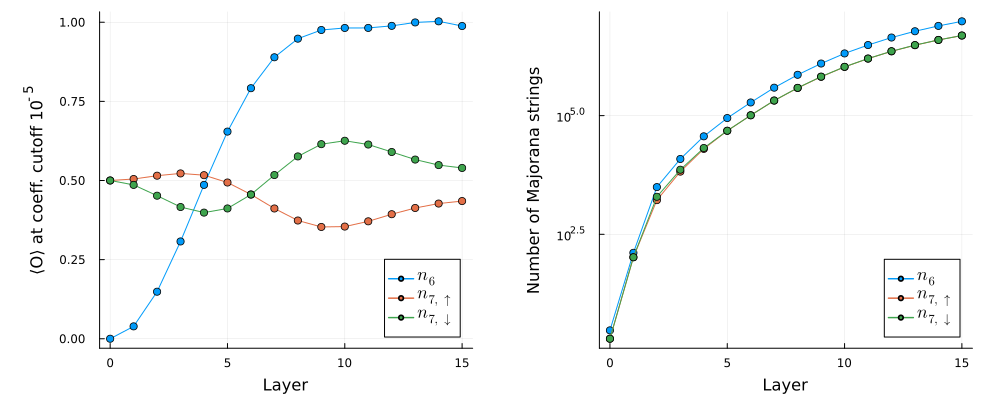

In [62]:
obs11 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, hole_pos)) #n_6_up
obs12 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, hole_pos)) #n_6_down
obs1=obs11+obs12
obs2 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :nup, 7)) #n_7_up
obs3 = VectorMajoranaSum(MajoranaSum(N_spinful_sites, :ndn, 7)) #n_7_down

res1 = zeros(n_layers+1)
res2 = zeros(n_layers+1)
res3 = zeros(n_layers+1)
length1 = zeros(n_layers+1)
length2 = zeros(n_layers+1)
length3 = zeros(n_layers+1)

res1[1]=overlapwithfock(obs1, initial_state, coeffs)
length1[1] = length(obs1)
res2[1]=overlapwithfock(obs2, initial_state, coeffs)
length2[1] = length(obs2)
res3[1]=overlapwithfock(obs3, initial_state, coeffs)
length3[1] = length(obs3)
#simulation (7down, 11up) for minal coefficient 1.e-5
for j = 1:n_layers 
    print("$j ")
    propagate!(circ_single, obs1, thetas_single; min_abs_coeff=min_abs_coeff2,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    propagate!(circ_single, obs2, thetas_single; min_abs_coeff=min_abs_coeff2,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    propagate!(circ_single, obs3, thetas_single; min_abs_coeff=min_abs_coeff2,max_unpaired=max_unpaired, unpaired_mask=unpaired_mask)
    res1[j+1] = overlapwithfock(obs1, initial_state, coeffs)
    res2[j+1] = overlapwithfock(obs2, initial_state, coeffs)
    res3[j+1] = overlapwithfock(obs3, initial_state, coeffs)

    length1[j+1] = length(obs1)
    length2[j+1] = length(obs2)
    length3[j+1] = length(obs3)
end

ev_plot = plot(xlabel = "Layer", ylabel = ylabel = "⟨O⟩ at coeff. cutoff " *"10^{-5}", legend = :bottomright, legend_font_pointsize = 12)
plot!(ev_plot, 0:n_layers, res1, label=L"n_6", marker=:circle)
plot!(ev_plot, 0:n_layers, res2, label=L"n_{7,\uparrow}", marker=:circle)
plot!(ev_plot, 0:n_layers, res3, label=L"n_{7,\downarrow}", marker=:circle)

length_plot = plot(xlabel = "Layer",ylabel = "Number of Majorana strings", yscale = :log10, legend = :bottomright,legend_font_pointsize = 12)
plot!(length_plot, 0:n_layers, length1, label=L"n_6", marker=:circle)
plot!(length_plot, 0:n_layers, length2, label=L"n_{7,\uparrow}", marker=:circle)
plot!(length_plot, 0:n_layers, length3, label=L"n_{7,\downarrow}", marker=:circle)

plot(ev_plot, length_plot, layout=(1,2), size=(1000,400),left_margin = 10mm, bottom_margin = 5mm, right_margin = 5mm)